# 05 Style axes: varimax-rotated principal components

Continuous style axes are the main way of describing fighters (clusters are secondary shorthand). Inputs: the 8 **era-relative**
style z-scores from `features.clustering_matrix(profiles)` (eligible fighters, full careers). Each fighter is standardized against
same-division fighters whose career midpoints are within ±4 years of theirs (see `docs/feature_spec.md`).

Method (`src/style_axes.py`): PCA on the z-scores, keep the first m components, then varimax-rotate their loadings. Axis scores are
standardized and uncorrelated, and loadings are feature–axis correlations. Axes are numbered by the variance they carry after rotation
and are **not named**.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))
import features as F
import style_axes as A

pd.set_option("display.width", 220, "display.precision", 3)
plt.rcParams.update({"figure.dpi": 80, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})
ff = F.load_fighter_fights()
profiles = F.build_profiles(None, ff)
X = F.clustering_matrix(profiles)
ev = np.sort(np.linalg.eigvalsh(np.cov(X.values, rowvar=False, ddof=0)))[::-1]
display(pd.DataFrame({"eigenvalue": ev.round(2), "explained": (ev / ev.sum()).round(3), "cumulative": (ev.cumsum() / ev.sum()).round(3)},
                     index=[f"PC{i + 1}" for i in range(len(ev))]).T)
print(f"{len(X):,} eligible fighters x {X.shape[1]} era-relative features")

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8
eigenvalue,2.890,1.450,0.900,0.840,0.600,0.570,0.480,0.160
explained,0.366,0.183,0.114,0.107,0.076,0.073,0.061,0.021
cumulative,0.366,0.549,0.663,0.769,0.845,0.918,0.979,1.000


1,240 eligible fighters x 8 era-relative features


## 1. Three or four axes?

Two criteria:

- **Stability.** Refit PCA + varimax on 200 bootstrap resamples of fighters, match each bootstrap axis to a full-data axis (Hungarian
  matching on |congruence|), and record (a) Tucker congruence of the loadings and (b) the correlation between bootstrap and full-data axis
  scores across all fighters. Values near 1 mean the axis reproduces.
- **Simple structure.** Does each feature load mainly on one axis?
  - purity: share of a feature's explained variance on its main axis
  - Hofmann complexity: 1 means the feature loads on a single axis
  - cross-loadings: features with |loading| ≥ 0.4 on more than one axis
  - communality: how much of each feature the axes capture

explained  congruence mean  congruence p5  score corr mean  score corr p5
axes axis                                                                             
3    axis_1      0.363            0.990          0.959            0.975          0.894
     axis_2      0.164            0.969          0.892            0.958          0.841
     axis_3      0.136            0.820          0.228            0.845          0.324
4    axis_1      0.321            0.998          0.996            0.998          0.994
     axis_2      0.165            0.996          0.990            0.997          0.991
     axis_3      0.148            0.992          0.979            0.993          0.979
     axis_4      0.135            0.993          0.982            0.995          0.987

,3,4
mean_purity,0.933,0.884
mean_complexity,1.155,1.323
cross_loading_features,0.000,1.000
features_without_salient_loading,0.000,0.000
axes_with_2plus_salient,2.000,3.000
min_communality,0.301,0.592


,3 axes,4 axes
communality,,
pos_clinch,0.68,0.68
pos_ground,0.65,0.66
tgt_body,0.68,0.70
tgt_leg,0.87,0.94
td_att_per15,0.65,0.74
ctrl_share,0.83,0.88
sub_att_per15,0.30,0.89
pace,0.57,0.59


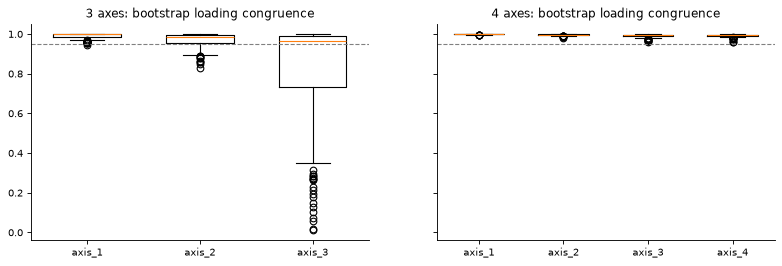

In [2]:
results = {}
for m in A.CANDIDATE_AXES:
    ax = A.fit_style_axes(profiles, m)
    b = A.bootstrap_stability(X, m, n_boot=200)
    ss = A.simple_structure(ax.loadings)
    results[m] = (ax, b, ss)
rows = []
for m, (ax, b, ss) in results.items():
    for j, name in enumerate(ax.axis_names):
        rows.append({"axes": m, "axis": name, "explained": ax.explained.iloc[j],
                     "congruence mean": b["congruence"][:, j].mean(), "congruence p5": np.quantile(b["congruence"][:, j], 0.05),
                     "score corr mean": b["score_corr"][:, j].mean(), "score corr p5": np.quantile(b["score_corr"][:, j], 0.05)})
display(pd.DataFrame(rows).set_index(["axes", "axis"]).round(3))
display(pd.DataFrame({m: {k: v for k, v in ss.items() if k != "communality"} for m, (_, _, ss) in results.items()}).round(3))
display(pd.DataFrame({f"{m} axes": ss["communality"] for m, (_, _, ss) in results.items()}).round(2).rename_axis("communality"))

fig, axes_ = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
for a, (m, (ax, b, ss)) in zip(axes_, results.items()):
    a.boxplot([b["congruence"][:, j] for j in range(m)], widths=0.6)
    a.set_xticks(range(1, m + 1), ax.axis_names)
    a.set_title(f"{m} axes: bootstrap loading congruence")
    a.axhline(0.95, color="grey", ls="--", lw=1)
plt.show()

**Choice: 4 axes** (`style_axes.CHOSEN_AXES`).

- **Stability.** With 4 axes, every axis reproduces almost perfectly under resampling: congruence and score correlation are about 0.99+,
  and even the 5th percentile is about 0.98. With 3 axes, the third axis is unstable (mean congruence about 0.8, with some resamples far lower).
  PCs 3 and 4 have nearly equal eigenvalues (0.90 vs 0.84), so keeping only 3 cuts through a near-tie, and which mix of the two the third
  axis captures changes from sample to sample. Keeping both resolves the tie.
- **Structure.** With 4 axes, every feature has a salient loading, each of 7 features loads mainly on one axis, and only pace splits across
  axes. With 3 axes, structure is marginally "purer", but submission attempts are poorly represented (communality about 0.3), so a
  distinct part of style is mostly lost.
- 4 axes carry 77% of the variance of the 8 inputs (3 axes carry 66%).

## 2. Loadings (4 axes)

Correlation between each era-relative feature and each axis. |loading| ≥ 0.4 is in bold.

In [3]:
axes4 = results[A.CHOSEN_AXES][0]
L = axes4.loadings
display(L.round(2).style.background_gradient(cmap="RdBu_r", vmin=-1, vmax=1).format("{:.2f}")
        .map(lambda v: "font-weight: bold" if abs(v) >= 0.4 else ""))
print("variance carried by each axis:", axes4.explained.round(3).to_dict(), "| total:", round(float(axes4.explained.sum()), 3))
for a in axes4.axis_names:
    s = L[a].sort_values()
    pos = ", ".join(f"{i} {v:+.2f}" for i, v in s[::-1].items() if v >= 0.3)
    neg = ", ".join(f"{i} {v:+.2f}" for i, v in s.items() if v <= -0.3)
    print(f"{a}: positive [{pos}]  negative [{neg or '-'}]")
print("\nFor comparison, 3 axes:")
display(results[3][0].loadings.round(2))

,axis_1,axis_2,axis_3,axis_4
pos_clinch,0.22,0.79,-0.03,-0.04
pos_ground,0.78,0.03,0.23,-0.04
tgt_body,-0.16,0.79,0.05,0.19
tgt_leg,-0.08,0.07,-0.06,0.96
td_att_per15,0.86,-0.04,0.05,-0.06
ctrl_share,0.92,0.05,0.15,-0.08
sub_att_per15,0.16,-0.01,0.92,-0.09
pace,-0.50,-0.17,-0.48,-0.28


variance carried by each axis: {'axis_1': 0.321, 'axis_2': 0.165, 'axis_3': 0.148, 'axis_4': 0.135} | total: 0.769
axis_1: positive [ctrl_share +0.92, td_att_per15 +0.86, pos_ground +0.78]  negative [pace -0.50]
axis_2: positive [tgt_body +0.79, pos_clinch +0.79]  negative [-]
axis_3: positive [sub_att_per15 +0.92]  negative [pace -0.48]
axis_4: positive [tgt_leg +0.96]  negative [-]

For comparison, 3 axes:


,axis_1,axis_2,axis_3
pos_clinch,0.20,0.80,-0.06
pos_ground,0.80,0.03,-0.07
tgt_body,-0.12,0.79,0.23
tgt_leg,-0.10,0.08,0.93
td_att_per15,0.80,-0.03,-0.14
ctrl_share,0.90,0.06,-0.13
sub_att_per15,0.53,-0.07,0.11
pace,-0.66,-0.15,-0.33


## 3. Fighters at each end of every axis (4 axes)

Eligible fighters, axis scores in SD units. Division and fight minutes are in parentheses.

In [4]:
scores = axes4.transform(profiles).merge(profiles[["fighter_id", "fight_time_min"]], on="fighter_id")
def ends(axis, n=10):
    fmt = lambda d: [f"{r.fighter_name} {getattr(r, axis):+.2f} ({r.division.replace('weight', 'wt')}, {r.fight_time_min:.0f}m)" for r in d.itertuples()]
    return pd.DataFrame({"highest": fmt(scores.nlargest(n, axis)), "lowest": fmt(scores.nsmallest(n, axis))}, index=range(1, n + 1))
for a in axes4.axis_names:
    print(f"\n=== {a} ===")
    display(ends(a))


=== axis_1 ===


,highest,lowest
1,"Khabib Nurmagomedov +3.74 (Lightwt, 172m)","Chris Lytle -2.60 (Welterwt, 216m)"
2,"Gregor Gillespie +3.66 (Lightwt, 59m)","Nam Phan -2.08 (Featherwt, 120m)"
3,"Tatiana Suarez +3.63 (Women's Strawwt, 113m)","Junior Dos Santos -2.08 (Heavywt, 247m)"
4,"Pat Sabatini +3.55 (Featherwt, 105m)","John Lineker -2.05 (Bantamwt, 188m)"
5,"Chael Sonnen +3.21 (Middlewt, 143m)","Irene Aldana -2.00 (Women's Bantamwt, 205m)"
6,"Merab Dvalishvili +3.20 (Bantamwt, 299m)","Max Holloway -2.00 (Featherwt, 534m)"
7,"Grant Dawson +3.14 (Lightwt, 170m)","John Makdessi -1.97 (Lightwt, 243m)"
8,"Anthony Hernandez +3.08 (Middlewt, 137m)","Tony Ferguson -1.97 (Lightwt, 272m)"
9,"Gillian Robertson +3.02 (Women's Flywt, 206m)","Chris Curtis -1.94 (Middlewt, 157m)"
10,"Jailton Almeida +3.02 (Heavywt, 92m)","Stefan Struve -1.91 (Heavywt, 188m)"



=== axis_2 ===


,highest,lowest
1,"Loma Lookboonmee +4.42 (Women's Strawwt, 145m)","Serghei Spivac -2.28 (Heavywt, 126m)"
2,"Chidi Njokuani +4.07 (Welterwt, 84m)","Yoshihiro Akiyama -2.25 (Middlewt, 92m)"
3,"Ben Saunders +3.85 (Welterwt, 150m)","Renato Moicano -2.17 (Lightwt, 188m)"
4,"Anthony Hamilton +3.77 (Heavywt, 63m)","Sean Brady -2.14 (Welterwt, 147m)"
5,"Frankie Saenz +3.33 (Bantamwt, 129m)","Khabib Nurmagomedov -2.14 (Lightwt, 172m)"
6,"Yana Santos +3.26 (Women's Bantamwt, 154m)","Francis Marshall -2.06 (Featherwt, 74m)"
7,"Demetrious Johnson +3.20 (Flywt, 334m)","Sergio Pettis -2.03 (Flywt, 211m)"
8,"Fabio Maldonado +3.19 (Light Heavywt, 135m)","Thiago Alves -1.95 (Welterwt, 297m)"
9,"Drakkar Klose +3.05 (Lightwt, 151m)","Marvin Vettori -1.92 (Middlewt, 309m)"
10,"Lina Lansberg +3.00 (Women's Bantamwt, 145m)","Calvin Kattar -1.92 (Featherwt, 222m)"



=== axis_3 ===


,highest,lowest
1,"Charles Oliveira +5.44 (Lightwt, 295m)","Corey Anderson -2.25 (Light Heavywt, 163m)"
2,"Aleksei Oleinik +4.24 (Heavywt, 116m)","Colby Covington -2.24 (Welterwt, 288m)"
3,"Jaqueline Amorim +4.04 (Women's Strawwt, 60m)","Curtis Blaydes -2.09 (Heavywt, 194m)"
4,"TJ Waldburger +3.73 (Welterwt, 59m)","Kamaru Usman -2.00 (Welterwt, 364m)"
5,"Jim Miller +3.59 (Lightwt, 453m)","Cain Velasquez -1.98 (Heavywt, 111m)"
6,"Stefan Struve +3.52 (Heavywt, 188m)","Michael Bisping -1.94 (Middlewt, 366m)"
7,"Paul Sass +3.50 (Lightwt, 28m)","Merab Dvalishvili -1.93 (Bantamwt, 299m)"
8,"Cole Miller +3.25 (Featherwt, 202m)","Jared Gordon -1.93 (Lightwt, 188m)"
9,"Frank Mir +3.23 (Heavywt, 156m)","Sean Strickland -1.89 (Middlewt, 407m)"
10,"Mayra Bueno Silva +3.10 (Women's Bantamwt, 161m)","Sam Stout -1.88 (Lightwt, 238m)"



=== axis_4 ===


,highest,lowest
1,"Chris Gutierrez +6.14 (Bantamwt, 203m)","Evan Dunham -2.88 (Lightwt, 230m)"
2,"Caol Uno +3.53 (Lightwt, 124m)","Brandon Royval -2.39 (Flywt, 152m)"
3,"Armen Petrosyan +3.49 (Middlewt, 84m)","Darren Elkins -2.30 (Featherwt, 351m)"
4,"Chris Padilla +3.46 (Lightwt, 53m)","Sean Strickland -2.26 (Middlewt, 407m)"
5,"Nathaniel Wood +3.26 (Featherwt, 190m)","Joe Lauzon -2.24 (Lightwt, 213m)"
6,"Johnny Walker +3.08 (Light Heavywt, 108m)","Kevin Lee -2.24 (Lightwt, 217m)"
7,"Jordan Leavitt +3.02 (Lightwt, 72m)","Nam Phan -2.15 (Featherwt, 120m)"
8,"Brandon Vera +2.93 (Light Heavywt, 164m)","Alex Morono -2.15 (Welterwt, 285m)"
9,"Andre Lima +2.80 (Flywt, 66m)","Frank Camacho -2.12 (Lightwt, 67m)"
10,"Pat Barry +2.80 (Heavywt, 69m)","Kennedy Nzechukwu -2.10 (Light Heavywt, 133m)"


## 4. Are the axes free of era and division?

Correlation of axis scores with career midpoint, and mean axis score by division and by career-midpoint era.

In [5]:
era = pd.cut(scores["career_mid"], [1999, 2008, 2014, 2020, 2027], labels=["2000-07", "2008-13", "2014-19", "2020-26"])
print("corr with career midpoint:", {a: round(float(scores[a].corr(scores["career_mid"])), 3) for a in axes4.axis_names})
display(scores.groupby(era, observed=True)[axes4.axis_names].mean().round(2).assign(fighters=scores.groupby(era, observed=True).size()))
display(scores.groupby("division")[axes4.axis_names].mean().round(2).assign(fighters=scores.groupby("division").size()))
# the same axes computed on division-only z-scores, for contrast
Xdiv = profiles[profiles["eligible"] & profiles["std_group"].notna()].set_index("fighter_id")[[f"zdiv_{f}" for f in F.CLUSTER_FEATURES]]
Xdiv.columns = axes4.feature_columns
sdiv = axes4.scores(Xdiv)
cm = profiles.set_index("fighter_id").loc[sdiv.index, "career_mid"]
print("same transformation applied to division-only z-scores, corr with career midpoint:",
      {a: round(float(sdiv[a].corr(cm)), 3) for a in axes4.axis_names})

corr with career midpoint: {'axis_1': -0.016, 'axis_2': -0.015, 'axis_3': -0.015, 'axis_4': -0.0}


,axis_1,axis_2,axis_3,axis_4,fighters
career_mid,,,,,
2000-07,0.04,0.10,0.06,-0.01,67
2008-13,0.05,0.03,0.05,-0.01,238
2014-19,-0.01,-0.02,-0.01,0.02,405
2020-26,-0.02,-0.01,-0.02,-0.01,530


,axis_1,axis_2,axis_3,axis_4,fighters
division,,,,,
Bantamweight,0.00,0.02,0.01,-0.01,120
Featherweight,-0.01,0.00,-0.01,-0.01,128
Flyweight,-0.01,0.02,-0.02,-0.01,74
Heavyweight,0.03,0.00,-0.01,-0.02,96
Light Heavyweight,-0.01,-0.03,0.01,0.01,99
Lightweight,0.00,-0.01,0.00,0.00,206
Middleweight,0.00,0.02,0.01,0.01,177
Welterweight,0.00,-0.01,-0.00,0.00,186
Women's Bantamweight,0.00,-0.05,0.09,0.08,41


same transformation applied to division-only z-scores, corr with career midpoint: {'axis_1': -0.176, 'axis_2': -0.108, 'axis_3': -0.188, 'axis_4': 0.035}


## 5. Saved outputs

`python src/style_axes.py` writes `data/processed/style_axes.csv` (each eligible fighter's 4 axis scores) and
`data/processed/models/style_axes_m4.joblib` (also `_m3`). Load the transformation with `style_axes.StyleAxes.load(path)` and apply it
to `features.build_profiles(as_of=...)` with `.transform(profiles)`. Leakage caveats are in `docs/style_axes.md`.

In [6]:
saved = A.StyleAxes.load(A.MODEL_DIR / f"style_axes_m{A.CHOSEN_AXES}.joblib")
chk = saved.transform(profiles)
print("saved transformation reproduces these scores:", np.allclose(chk[saved.axis_names].values, scores[saved.axis_names].values))
print(saved.metadata)

saved transformation reproduces these scores: True
{'fitted_at_utc': '2026-11-21T00:43:13+00:00', 'profiles_as_of': None, 'n_fighters': 1240, 'n_axes': 4, 'era_window_years': 4.0, 'era_min_ref': 30, 'prior_minutes': 60.0, 'feature_priors': {'sub_att_per15': 240.0}, 'min_fights': 5, 'start_date': '2000-01-01'}
